# Distingue variabilidad de proceso e incertidumbre

**Pregunta:** ¿Cómo cambia el análisis «Distingue variabilidad de proceso e incertidumbre» al ejecutar el mismo mineral de autoría propia con tratamientos controlados?

Nivel: 1. Requisitos previos: Nivel 1 de aprendizaje. Tiempo de lectura: 18 minutos.

## Objetivos

Lee el registro de incertidumbre comprometido, identifica sus entradas inciertas y cuantiles de salida, y explica por qué un intervalo de un estado simulado no es un intervalo de confianza de planta.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/benchmark.json` y `data/derived/studies.json`, licencia MIT del proyecto. Los rangos son supuestos de incertidumbre aplicados a casos de proceso propios; las etiquetas son simuladas. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

OreFlow varía índice de trabajo, ley de cabeza, tamaño de liberación y flotabilidad dentro de rangos multiplicativos declarados, y resuelve nuevamente el mismo circuito estacionario. Un hipercubo latino con semilla genera muestras reproducibles. Los cuantiles describen este modelo y estos rangos; no estiman error de medición de terreno ni variabilidad entre plantas.

Carga los cuantiles de incertidumbre y el estudio de semillas repetidas para el mismo caso de autoría propia.

In [2]:
# Carga los cuantiles de incertidumbre y el estudio de semillas repetidas para el mismo caso de
# autoría propia.
repo = Path("../../../").resolve()
benchmark = json.loads((repo / "data/derived/benchmark.json").read_text(encoding="utf-8"))
studies = json.loads((repo / "data/derived/studies.json").read_text(encoding="utf-8"))
record = benchmark["uncertainty"]["copper_porphyry_soft"]
seed_study = studies["cases"]["copper_porphyry_soft"]["seed_study"]
print(
    "design:",
    seed_study["design"],
    "| samples:",
    seed_study["samples"],
    "| seeds:",
    len(seed_study["seeds"]),
)
display(
    pd.DataFrame(
        [
            {"output": name, **summary}
            for name, summary in record.items()
            if isinstance(summary, dict) and "p50" in summary
        ]
    ).set_index("output")
)


design: Latin hypercube | samples: 128 | seeds: 8


,p05,p50,p95
output,,,
recovery_pct,89.410940,91.897183,93.795676
concentrate_grade,24.868232,26.441278,27.709650


Compara la entrada que domina la dispersión de recuperación con el rango P05-P95. Son propiedades del dominio de simulación declarado.

In [3]:
# Compara la entrada que domina la dispersión de recuperación con el rango P05-P95.
print("dominant input by output:", record["dominant_input"])
print("all-constraint probability:", record["probabilities"]["all_constraints"])
seed_rows = pd.DataFrame(
    [
        {
            "seed": item["seed"],
            "recovery P05": item["recovery_pct"]["p05"],
            "recovery P50": item["recovery_pct"]["p50"],
            "recovery P95": item["recovery_pct"]["p95"],
            "all constraints": item["all_constraints"],
        }
        for item in seed_study["per_seed"]
    ]
)
display(seed_rows)


dominant input by output: {'recovery_pct': 'floatability', 'concentrate_grade': 'liberation_size', 'specific_energy_grinding_kwh_t': 'work_index', 'recovered_primary_tph': 'head_grade'}
all-constraint probability: 0.8203125


,seed,recovery P05,recovery P50,recovery P95,all constraints
0,101,89.216297,91.996411,94.025237,0.820312
1,202,89.018685,91.983648,94.034888,0.820312
2,303,89.042295,91.985040,93.914918,0.812500
3,404,89.367639,91.975672,93.875840,0.812500
4,505,89.079242,92.035955,93.745444,0.820312
5,606,89.087326,91.944077,93.799518,0.812500
6,707,89.374171,92.092473,94.007753,0.812500
7,808,89.294996,91.917077,93.948797,0.812500


Para el caso de nivel 1 sobre 05 uncertainty, solo cambia la alimentación fresca con 0.9 veces el tratamiento nominal. Esta comparación de nivel 1 sobre 05 uncertainty, con 0.9 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [4]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.9
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('tratamiento (t/h):', round(point_1.throughput_tph, 2))
print('recuperación (%):', round(response_1.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_1.metrics['p80_um'], 2))

tratamiento (t/h): 648.0
recuperación (%): 92.996
P80 de producto (µm): 150.0


Para el caso de nivel 1 sobre 05 uncertainty, solo cambia la alimentación fresca con 1.0 veces el tratamiento nominal. Esta comparación de nivel 1 sobre 05 uncertainty, con 1.0 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [5]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 1.0
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('tratamiento (t/h):', round(point_2.throughput_tph, 2))
print('recuperación (%):', round(response_2.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_2.metrics['p80_um'], 2))

tratamiento (t/h): 720.0
recuperación (%): 92.213
P80 de producto (µm): 150.0


Para el caso de nivel 1 sobre 05 uncertainty, solo cambia la alimentación fresca con 1.1 veces el tratamiento nominal. Esta comparación de nivel 1 sobre 05 uncertainty, con 1.1 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [6]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.1
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('tratamiento (t/h):', round(point_3.throughput_tph, 2))
print('recuperación (%):', round(response_3.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_3.metrics['p80_um'], 2))

tratamiento (t/h): 792.0
recuperación (%): 91.437
P80 de producto (µm): 150.0


En el nivel 1 de 05 uncertainty, los paneles usan los mismos ajustes y 3 puntos resueltos por el modelo, no observaciones de planta. En el nivel 1, la tendencia de 05 uncertainty es la respuesta local de un caso de autoría propia y puede cambiar cerca de límites de potencia o ley; no estima un efecto causal en planta.

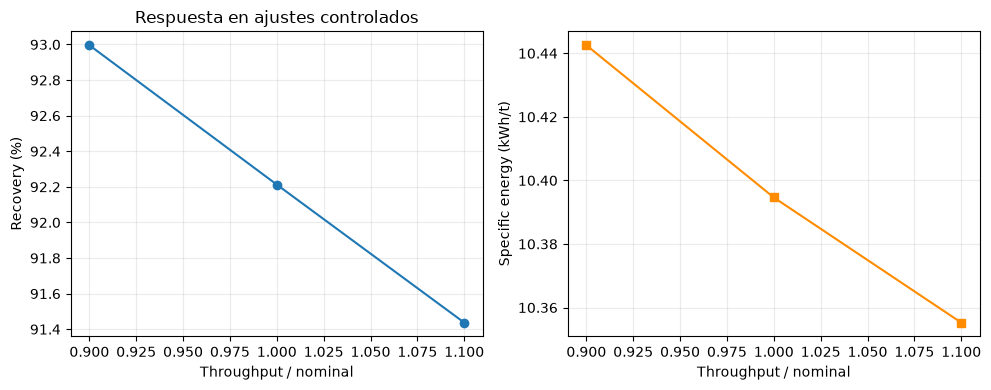

In [7]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.9, 1.0, 1.1]
runs = [response_1, response_2, response_3]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Respuesta en ajustes controlados')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

En el análisis de nivel 1 sobre 05 uncertainty, lee esta respuesta de tamaño junto a los paneles de recuperación y energía, no como sustituto. En el nivel 1, un objetivo de molienda constante en este caso de 05 uncertainty puede mantener P80 casi sin cambio mientras potencia, recirculación y residencia alteran otras salidas. Para 05 uncertainty en nivel 1, conserva las alertas del modelo y la auditoría de balance junto con el resultado.

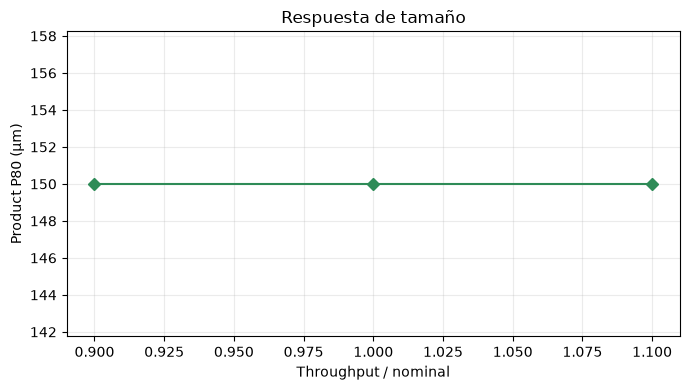

In [8]:
# # Muestra el tamaño de producto aparte: se mide en micrómetros, no en energía o recuperación.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Respuesta de tamaño')
ax.grid(True, alpha=0.25)
fig.tight_layout()

En el nivel 1 de 05 uncertainty, la interpretación 1 es que la dispersión de escenarios está condicionada por las distribuciones elegidas, los supuestos de dependencia, el diseño muestral y las ecuaciones de proceso. En el nivel 1 de 05 uncertainty, la interpretación 2 es que la propagación de incertidumbre de OreFlow muestrea factores operativos y minerales acotados, ejecuta el motor exacto del circuito y resume cuantiles de respuesta y probabilidades de restricciones. En el nivel 1 de 05 uncertainty, la interpretación 3 es que una descomposición de Sobol pregunta cómo contribuye la variación de entradas a la varianza de salida bajo sus supuestos de muestreo. En el nivel 1 de 05 uncertainty, la interpretación 4 es que no asigna probabilidades al yacimiento ni establece causalidad. En el nivel 1 de 05 uncertainty, la interpretación 5 es que los índices de primer orden y de orden total responden preguntas distintas porque el orden total incluye interacciones. En el nivel 1 de 05 uncertainty, la interpretación 6 es que las semiamplitudes bootstrap describen estabilidad del estimador para ese diseño, no incertidumbre de la planta real. En el nivel 1 de 05 uncertainty, la interpretación 7 es que informa siempre semilla aleatoria, tamaño de muestra base, límites de entradas, sorteos rechazados y si la salida fue constante dentro de la tolerancia numérica. En el nivel 1 de 05 uncertainty, la interpretación 8 es que sorteos independientes pueden crear combinaciones físicamente improbables cuando variables geológicas covarían, mientras que límites estrechos pueden hacer parecer irrelevante un factor influyente. En el nivel 1 de 05 uncertainty, la interpretación 9 es que separa incertidumbre de entradas de incertidumbre estructural del modelo y error de medición. En el nivel 1 de 05 uncertainty, la interpretación 10 es que para interpretar una decisión, propaga distribuciones calibradas, compara intervalos con campañas de planta reservadas y evalúa si se mantiene el orden de las alternativas operativas. En el nivel 1 de 05 uncertainty, la interpretación 11 es que los escenarios actuales de autoría propia permiten inspeccionar el método y repetirlo. En el nivel 1 de 05 uncertainty, la interpretación 12 es que no entregan un pronóstico probabilístico de una mina o planta.

## Resultados

**Respuesta:** En esta lección de nivel 1 sobre 05 uncertainty, el circuito ejecutado informa una recuperación de 92.996 por ciento para «Distingue variabilidad de proceso e incertidumbre» en el primer tratamiento controlado.

Los cuantiles resumen la salida del modelo condicionada por las semiamplitudes de autoría y el caso elegido. El estudio de semillas muestra cómo cambian estimaciones con otro diseño. Ninguno describe incertidumbre observacional real sin mediciones independientes y un modelo de incertidumbre justificado.

## Resumen

Separaste un estudio de incertidumbre simulada con semilla de la incertidumbre de medición. Al citar resultados, declara diseño, rangos de entrada y procedencia de datos.

## Referencias

- https://doi.org/10.1080/00401706.1979.10489755